## Descriptive Statistics

This script provides an Overview of the two datasets/their characteristics

In [10]:
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

DB_PATH = "PJDB.db"

plt.rcParams.update({"figure.dpi": 130, "font.size": 11})

with sqlite3.connect(DB_PATH) as conn:
    kununu   = pd.read_sql("SELECT * FROM REVIEWS_GER", conn)
    glassdoor = pd.read_sql("SELECT * FROM reviews_clean", conn)
    n_llm_gd  = pd.read_sql("SELECT COUNT(*) AS n FROM classifications_llm", conn).iloc[0, 0]
    n_human   = pd.read_sql("SELECT COUNT(*) AS n FROM human_validation", conn).iloc[0, 0]

kununu["rating"]          = pd.to_numeric(kununu["rating"], errors="coerce")
kununu["date"]            = pd.to_datetime(kununu["date"], errors="coerce")
glassdoor["overall_rating"] = pd.to_numeric(glassdoor["overall_rating"], errors="coerce")
glassdoor["date_review"]    = pd.to_datetime(glassdoor["date_review"], errors="coerce")

print(f"Kununu:    {len(kununu):>7,} reviews  |  {kununu['company'].nunique()} companies")
print(f"Glassdoor: {len(glassdoor):>7,} reviews  |  {glassdoor['firm'].nunique()} companies")
print(f"  └ LLM classified subset: {n_llm_gd:,}")
print(f"Human validation: {n_human} reviews")

Kununu:     19,370 reviews  |  46 companies
Glassdoor: 836,254 reviews  |  428 companies
  └ LLM classified subset: 114,325
Human validation: 238 reviews


### Sample Overview

In [ ]:
#  Sample overview table 
k_pros_filled = (kununu["pros"].notna() & (kununu["pros"] != "")).sum()
k_cons_filled = (kununu["cons"].notna() & (kununu["cons"] != "")).sum()
g_pros_filled = (glassdoor["pros"].notna() & (glassdoor["pros"] != "")).sum()
g_cons_filled = (glassdoor["cons"].notna() & (glassdoor["cons"] != "")).sum()

k_pros_words = kununu["pros"].fillna("").str.split().str.len()
k_cons_words = kununu["cons"].fillna("").str.split().str.len()
g_pros_words = glassdoor["pros"].fillna("").str.split().str.len()
g_cons_words = glassdoor["cons"].fillna("").str.split().str.len()

overview = pd.DataFrame({
    "Kununu": [
        f"{len(kununu):,}",
        str(kununu["company"].nunique()),
        f"{kununu['date'].dt.year.min()}–{kununu['date'].dt.year.max()}",
        f"{kununu['rating'].mean():.2f}  (SD {kununu['rating'].std():.2f})",
        f"{k_pros_filled:,}  ({k_pros_filled/len(kununu)*100:.0f}%)",
        f"{k_cons_filled:,}  ({k_cons_filled/len(kununu)*100:.0f}%)",
        f"Pros {k_pros_words[k_pros_words>0].median():.0f}  |  Cons {k_cons_words[k_cons_words>0].median():.0f}",
        "German",
    ],
    "Glassdoor": [
        f"{len(glassdoor):,}  ({n_llm_gd:,} classified)",
        str(glassdoor["firm"].nunique()),
        f"{glassdoor['date_review'].dt.year.min()}–{glassdoor['date_review'].dt.year.max()}",
        f"{glassdoor['overall_rating'].mean():.2f}  (SD {glassdoor['overall_rating'].std():.2f})",
        f"{g_pros_filled:,}  ({g_pros_filled/len(glassdoor)*100:.0f}%)",
        f"{g_cons_filled:,}  ({g_cons_filled/len(glassdoor)*100:.0f}%)",
        f"Pros {g_pros_words[g_pros_words>0].median():.0f}  |  Cons {g_cons_words[g_cons_words>0].median():.0f}",
        "English",
    ],
}, index=["N reviews", "N companies", "Year range", "Mean rating (1–5)",
          "Pros filled", "Cons filled", "Median words (non-empty)", "Language"])

display(overview)

,Kununu,Glassdoor
N reviews,"19,370","836,254 (114,325 classified)"
N companies,46,428
Year range,2008–2026,2008–2021
Mean rating (1–5),3.57 (SD 1.15),3.66 (SD 1.17)
Pros filled,"12,710 (66%)","836,252 (100%)"
Cons filled,"11,056 (57%)","836,241 (100%)"
Median words (non-empty),Pros 6 | Cons 8,Pros 9 | Cons 9
Language,German,English


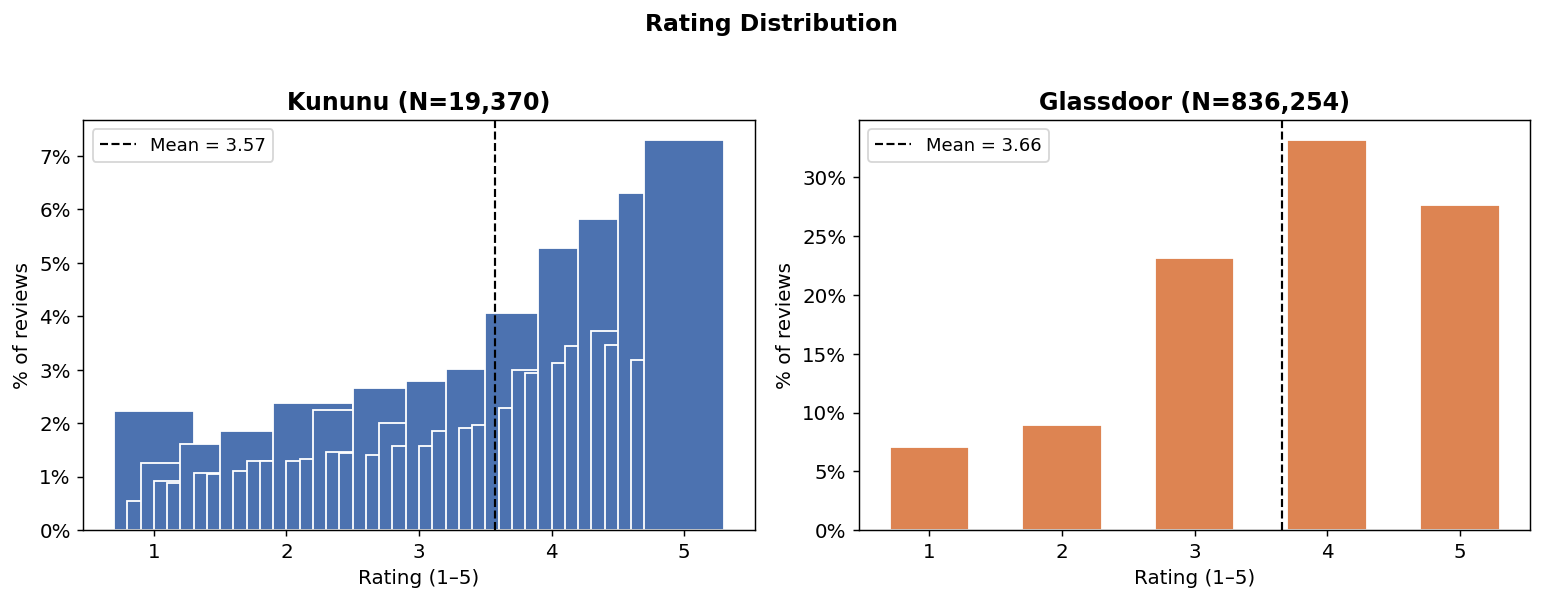

In [ ]:
#  Rating distributions 
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=False)

for ax, df, title, color in zip(
    axes,
    [kununu, glassdoor],
    ["Kununu (N=19,370)", "Glassdoor (N=836,254)"],
    ["#4C72B0", "#DD8452"],
):
    col = "rating" if "rating" in df.columns else "overall_rating"
    counts = df[col].dropna().value_counts().sort_index()
    ax.bar(counts.index, counts.values / counts.sum() * 100, color=color, width=0.6, edgecolor="white")
    ax.set_title(title, fontweight="bold")
    ax.set_xlabel("Rating (1–5)")
    ax.set_ylabel("% of reviews")
    ax.set_xticks([1, 2, 3, 4, 5])
    ax.yaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
    mean_val = df[col].mean()
    ax.axvline(mean_val, color="black", linestyle="--", linewidth=1.2, label=f"Mean = {mean_val:.2f}")
    ax.legend(fontsize=10)

fig.suptitle("Rating Distribution", fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

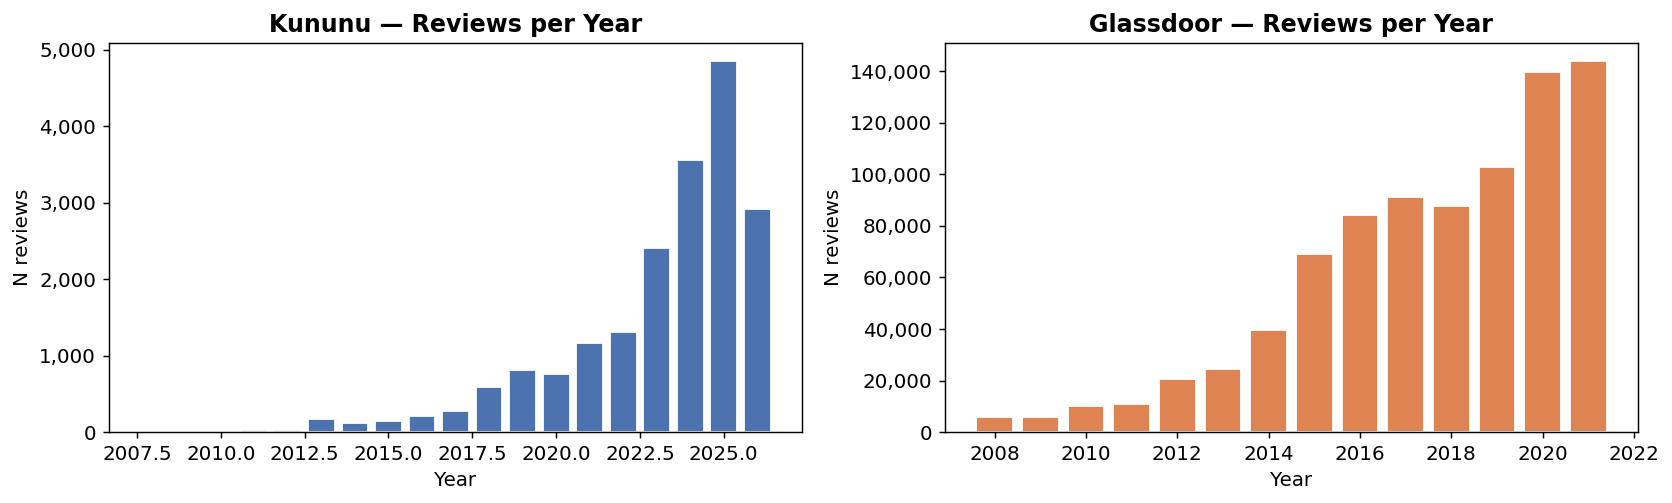

In [ ]:
# Reviews per year 
k_year = kununu["date"].dt.year.value_counts().sort_index()
g_year = glassdoor["date_review"].dt.year.value_counts().sort_index()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].bar(k_year.index, k_year.values, color="#4C72B0", edgecolor="white")
axes[0].set_title("Kununu — Reviews per Year", fontweight="bold")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("N reviews")
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:,.0f}"))

axes[1].bar(g_year.index, g_year.values, color="#DD8452", edgecolor="white")
axes[1].set_title("Glassdoor — Reviews per Year", fontweight="bold")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("N reviews")
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:,.0f}"))

plt.tight_layout()
plt.show()

In [ ]:
#  Text length distribution (word counts, capped at 100 for readability)
fig, axes = plt.subplots(2, 2, figsize=(13, 7), sharey=False)

datasets = [
    (kununu,    "Kununu",    "#4C72B0"),
    (glassdoor, "Glassdoor", "#DD8452"),
]

for col_idx, (df, label, color) in enumerate(datasets):
    pros_col = "pros"
    cons_col = "cons"
    for row_idx, field in enumerate(["pros", "cons"]):
        ax = axes[row_idx][col_idx]
        words = df[field].fillna("").str.split().str.len()
        words_ne = words[words > 0].clip(upper=150)
        ax.hist(words_ne, bins=40, color=color, edgecolor="white", alpha=0.85)
        ax.set_title(f"{label} — {field.capitalize()} (non-empty, N={len(words_ne):,})", fontweight="bold")
        ax.set_xlabel("Word count (capped at 150)")
        ax.set_ylabel("N reviews")
        med = words_ne.median()
        ax.axvline(med, color="black", linestyle="--", linewidth=1.2, label=f"Median = {med:.0f}")
        ax.legend(fontsize=9)
        ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:,.0f}"))

fig.suptitle("Text Length Distribution (Pros & Cons)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

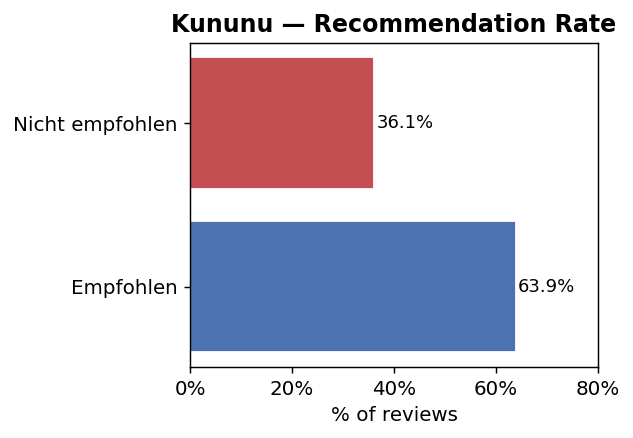

recommendation
Empfohlen          12125
Nicht empfohlen     6864


In [ ]:
#  Kununu: recommendation rates
rec = kununu["recommendation"].value_counts()
rec_pct = rec / rec.sum() * 100

fig, ax = plt.subplots(figsize=(5, 3.5))
bars = ax.barh(rec_pct.index, rec_pct.values, color=["#4C72B0", "#C44E52"], edgecolor="white")
for bar, val in zip(bars, rec_pct.values):
    ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height() / 2,
            f"{val:.1f}%", va="center", fontsize=10)
ax.set_title("Kununu — Recommendation Rate", fontweight="bold")
ax.set_xlabel("% of reviews")
ax.set_xlim(0, 80)
ax.xaxis.set_major_formatter(mticker.PercentFormatter(decimals=0))
plt.tight_layout()
plt.show()

print(rec.to_string())

Kununu — reviews per company:
  Min: 22  |  Median: 500  |  Max: 500



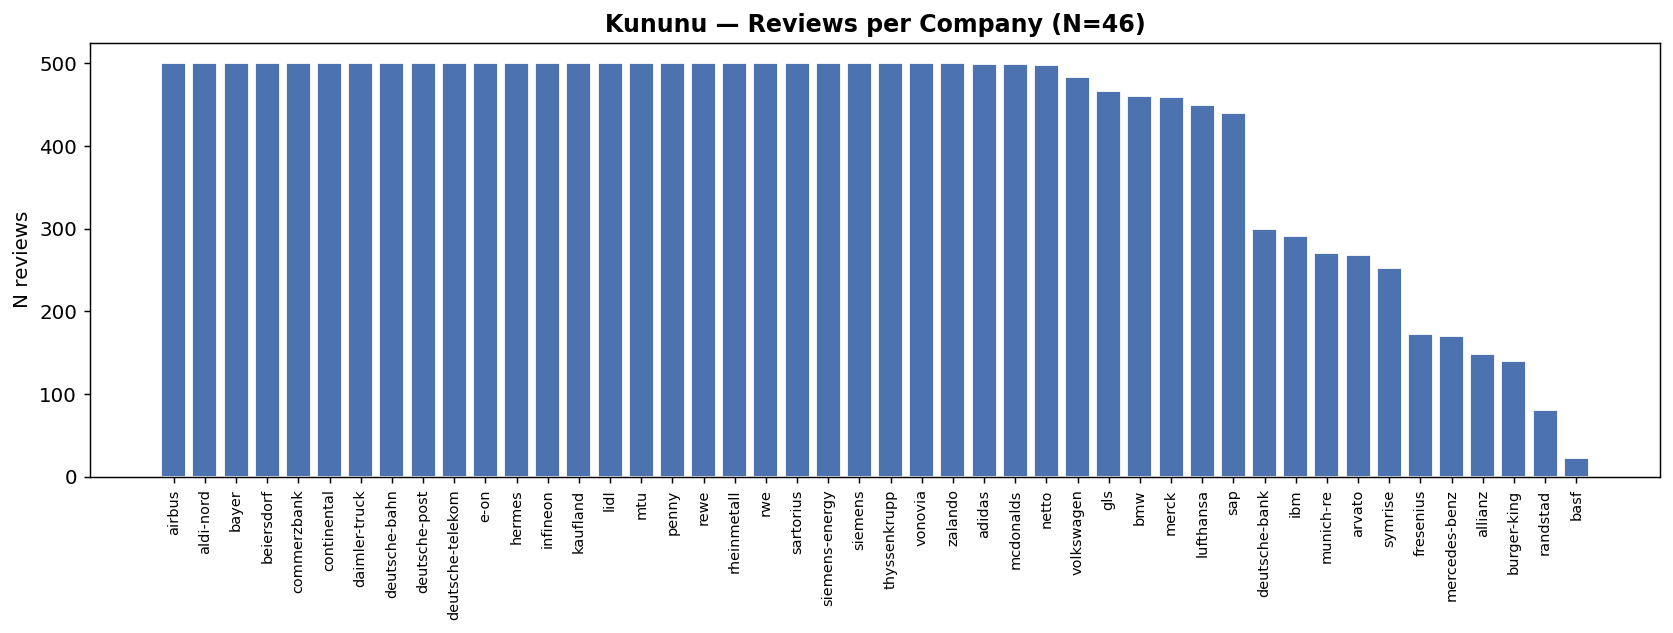

In [ ]:
#  Review counts per company (Kununu) 
comp_counts = kununu["company"].value_counts()
print("Kununu — reviews per company:")
print(f"  Min: {comp_counts.min()}  |  Median: {comp_counts.median():.0f}  |  Max: {comp_counts.max()}")
print()

fig, ax = plt.subplots(figsize=(13, 5))
ax.bar(range(len(comp_counts)), comp_counts.values, color="#4C72B0", edgecolor="white")
ax.set_xticks(range(len(comp_counts)))
ax.set_xticklabels(comp_counts.index, rotation=90, fontsize=8)
ax.set_ylabel("N reviews")
ax.set_title("Kununu — Reviews per Company (N=46)", fontweight="bold")
plt.tight_layout()
plt.show()

In [ ]:
# Human validation sample 
with sqlite3.connect(DB_PATH) as conn:
    human = pd.read_sql("SELECT * FROM human_validation", conn)
    human_text = pd.read_sql(
        "SELECT r.id, r.company, r.date FROM REVIEWS_GER r "
        "WHERE r.id IN (" + ",".join(human["review_id"].astype(str).tolist()) + ")",
        conn,
    )

human_text["date"] = pd.to_datetime(human_text["date"], errors="coerce")

print(f"Human validation: N = {len(human)} reviews")
print(f"Companies represented: {human_text['company'].nunique()}")
print(f"Year range: {human_text['date'].dt.year.min()}–{human_text['date'].dt.year.max()}")
print()
print("Company distribution:")
print(human_text["company"].value_counts().to_string())

Human validation: N = 238 reviews
Companies represented: 44
Year range: 2011–2026

Company distribution:
company
commerzbank         13
rheinmetall         12
bmw                 11
netto               10
adidas               9
bayer                8
deutsche-bahn        8
deutsche-post        8
merck                8
mtu                  8
penny                8
continental          7
siemens              7
volkswagen           7
aldi-nord            6
beiersdorf           6
deutsche-bank        6
kaufland             6
lidl                 6
rwe                  6
vonovia              6
airbus               5
deutsche-telekom     5
e-on                 5
hermes               5
mcdonalds            5
sap                  5
sartorius            5
lufthansa            4
rewe                 4
ibm                  3
infineon             3
mercedes-benz        3
munich-re            3
thyssenkrupp         3
zalando              3
arvato               2
fresenius            2
siemens-energ